In [27]:
import pandas as pd



# set pandas options
pd.set_option('display.max_rows', 500)
pd.set_option('display.max_columns', 100)
import os
path = r"C:/Users/axelk/Desktop/Intro_AI/assignment_Logistic_Regression"
filename = 'titanic.csv'
fullpath = os.path.join(path,filename)
axel = pd.read_csv(fullpath,sep=',')
print("--- First 3 Records ---")
print(axel.head(3))
print("\n--- Shape (Rows, Columns) ---")
print(axel.shape)


--- First 3 Records ---
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  

--- Shape (Rows, Columns) ---
(891, 12)


In [28]:
print("\n--- unique values for 'Sex' and 'Pclass' ---")
print("Unique values in 'Sex':", axel['Sex'].unique())
print("Unique values in 'Pclass':", axel['Pclass'].unique())


--- unique values for 'Sex' and 'Pclass' ---
Unique values in 'Sex': <StringArray>
['male', 'female']
Length: 2, dtype: str
Unique values in 'Pclass': [3 1 2]


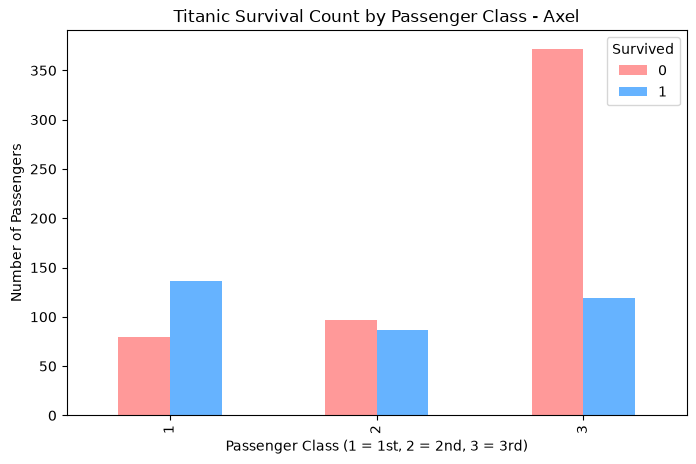

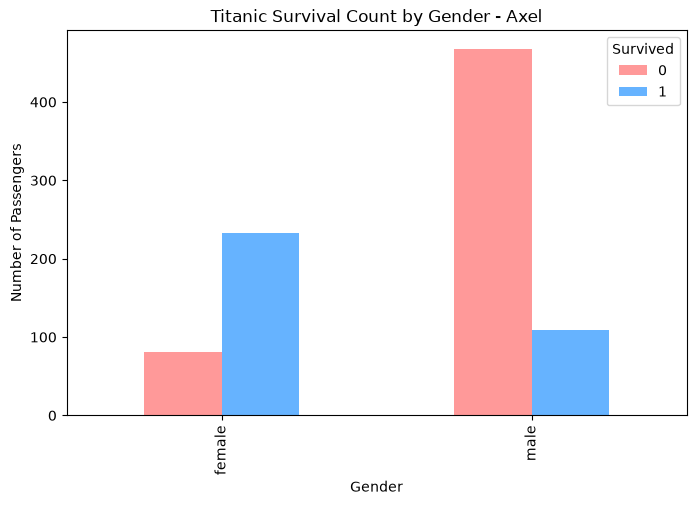

In [29]:
import pandas as pd
import matplotlib.pyplot as plt

ct_pclass = pd.crosstab(axel['Pclass'], axel['Survived'])
ax1 = ct_pclass.plot(kind='bar', figsize=(8, 5), color=['#ff9999', '#66b3ff'])
plt.title('Titanic Survival Count by Passenger Class - Axel')
plt.xlabel('Passenger Class (1 = 1st, 2 = 2nd, 3 = 3rd)')
plt.ylabel('Number of Passengers')
plt.show()

# --- Plot B: Survival vs. Gender ---
ct_sex = pd.crosstab(axel['Sex'], axel['Survived'])
ax2 = ct_sex.plot(kind='bar', figsize=(8, 5), color=['#ff9999', '#66b3ff'])
plt.title('Titanic Survival Count by Gender - Axel')
plt.xlabel('Gender')
plt.ylabel('Number of Passengers')
plt.show()

<Figure size 1000x1000 with 0 Axes>

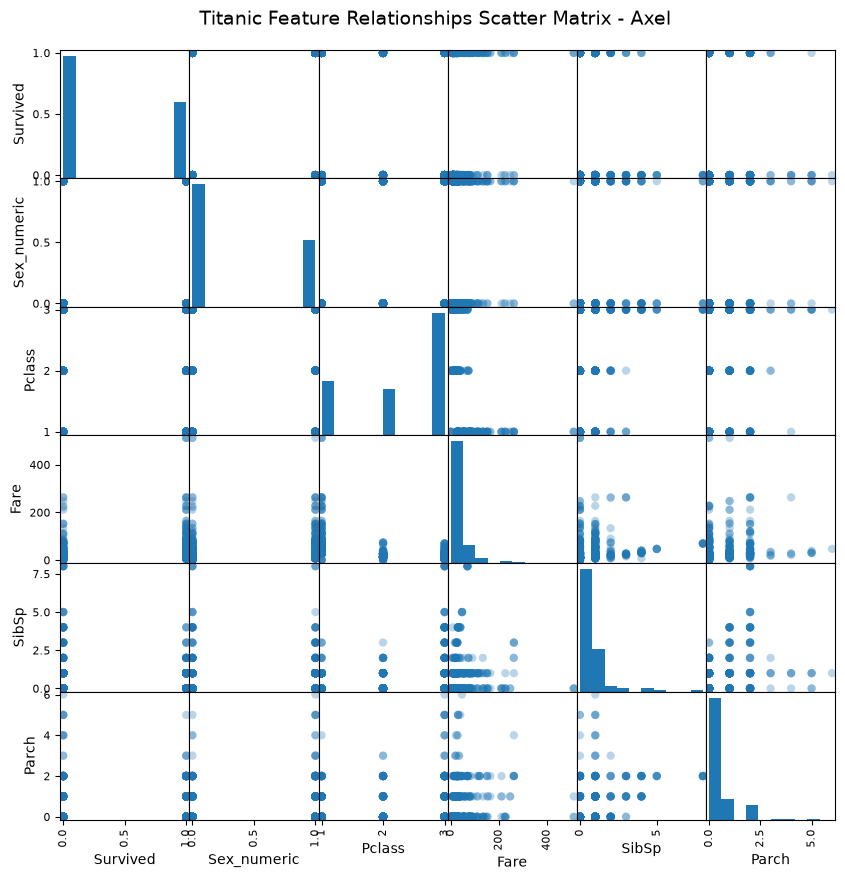

In [30]:
import pandas as pd
from pandas.plotting import scatter_matrix

axel['Sex_numeric'] = axel['Sex'].map({'female': 1, 'male': 0})

# Select the requested columns
features = ['Survived', 'Sex_numeric', 'Pclass', 'Fare', 'SibSp', 'Parch']
subset_df = axel[features]

# Generate scatter matrix
plt.figure(figsize=(10, 10))  
scatter_matrix(subset_df, alpha=0.3, figsize=(10, 10), diagonal='hist', marker='o')
plt.suptitle("Titanic Feature Relationships Scatter Matrix - Axel", fontsize=14, y=0.92)
plt.show()



# Transformer Sex et Embarked en colonnes numériques (préfixes Sex_ et Embarked_)
axel = pd.get_dummies(axel, columns=['Sex', 'Embarked'])





In [31]:
axel = axel.drop(columns=['Sex_numeric'])

# Supprimer les 4 colonnes inutiles
axel = axel.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin'])
print("\n--- DataFrame after dropping unnecessary columns ---")
print(axel.columns)


--- DataFrame after dropping unnecessary columns ---
Index(['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Sex_female',
       'Sex_male', 'Embarked_C', 'Embarked_Q', 'Embarked_S'],
      dtype='str')


In [32]:

# 1. Replace missing values in Age with the mean
axel['Age'] = axel['Age'].fillna(axel['Age'].mean())

# 2. Convert all columns to float
axel = axel.astype(float)

# 3. Check the info
axel.info()



<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Survived    891 non-null    float64
 1   Pclass      891 non-null    float64
 2   Age         891 non-null    float64
 3   SibSp       891 non-null    float64
 4   Parch       891 non-null    float64
 5   Fare        891 non-null    float64
 6   Sex_female  891 non-null    float64
 7   Sex_male    891 non-null    float64
 8   Embarked_C  891 non-null    float64
 9   Embarked_Q  891 non-null    float64
 10  Embarked_S  891 non-null    float64
dtypes: float64(11)
memory usage: 76.7 KB


In [7]:
def normalize_df(dataframe):
    return (dataframe - dataframe.min()) / (dataframe.max() - dataframe.min())

df_normalized = normalize_df(axel)
print(df_normalized.head(2))

   Survived  Pclass       Age  SibSp  Parch      Fare  Sex_female  Sex_male  \
0       0.0     1.0  0.271174  0.125    0.0  0.014151         0.0       1.0   
1       1.0     0.0  0.472229  0.125    0.0  0.139136         1.0       0.0   

   Embarked_C  Embarked_Q  Embarked_S  
0         0.0         0.0         1.0  
1         1.0         0.0         0.0  


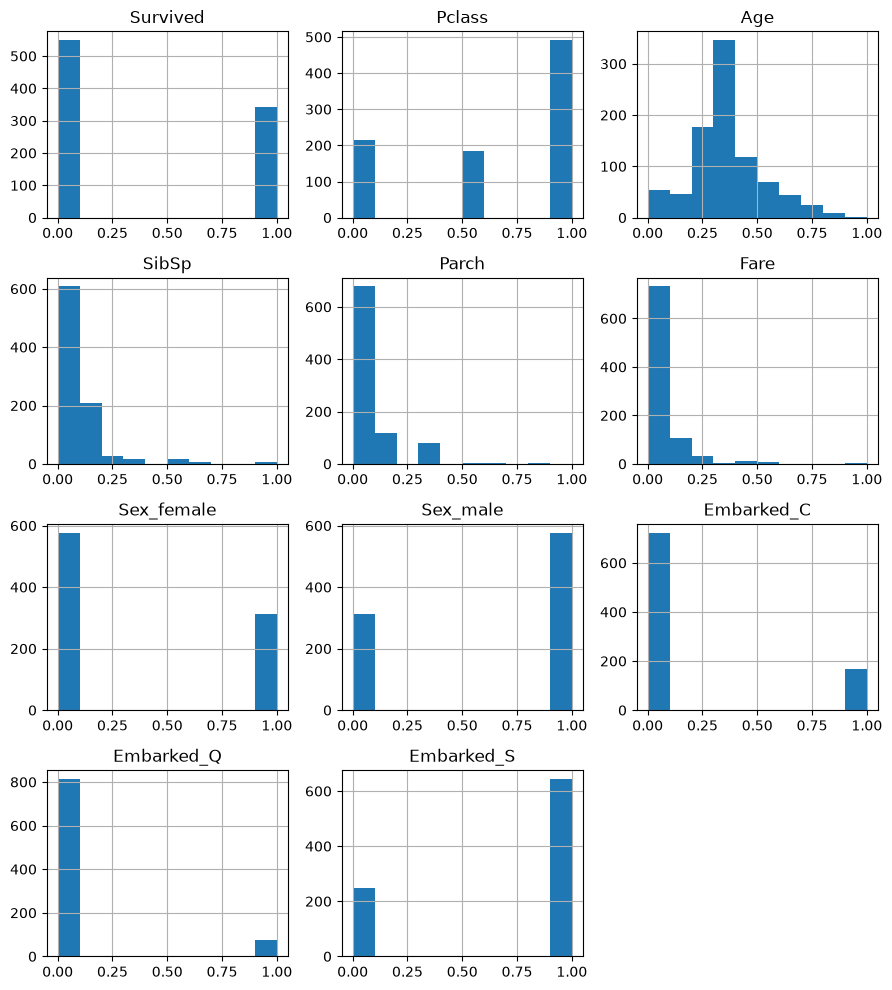

In [8]:

# Histogrammes 
df_normalized.hist(figsize=(9, 10))
plt.tight_layout()
plt.show()





In [9]:
# Split features into x_firstname (dropping the target column 'Survived')
x_axel = df_normalized.drop(columns=['Survived'])

# Split the target class into y_firstname (keeping only 'Survived')
y_axel = df_normalized[['Survived']]
print("Features dataframe shape (x_axel):", x_axel.shape)
print("Target dataframe shape (y_axel):", y_axel.shape)

Features dataframe shape (x_axel): (891, 10)
Target dataframe shape (y_axel): (891, 1)


In [10]:
from sklearn.model_selection import train_test_split

x_train_axel, x_test_axel, y_train_axel, y_test_axel = train_test_split(
    x_axel, 
    y_axel, 
    test_size=0.30, 
    random_state=42
)

# Verify the shapes of the resulting datasets
print("x_train shape:", x_train_axel.shape)
print("x_test shape:", x_test_axel.shape)
print("y_train shape:", y_train_axel.shape)
print("y_test shape:", y_test_axel.shape)

x_train shape: (623, 10)
x_test shape: (268, 10)
y_train shape: (623, 1)
y_test shape: (268, 1)


In [11]:
import numpy as np
from sklearn.linear_model import LogisticRegression

axel_model = LogisticRegression(random_state=42)

# Fit the model using the training data
axel_model.fit(x_train_axel, y_train_axel)

print("Model successfully trained!")
print("Model parameters:", axel_model.get_params())


coef_axel = pd.DataFrame(
    list(zip(x_train_axel.columns, np.transpose(axel_model.coef_))), 
    columns=['Feature', 'Coefficient']
)

# Display the coefficient table
print(coef_axel)

Model successfully trained!
Model parameters: {'C': 1.0, 'class_weight': None, 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': 0.0, 'max_iter': 100, 'n_jobs': None, 'penalty': 'deprecated', 'random_state': 42, 'solver': 'lbfgs', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}
      Feature             Coefficient
0      Pclass   [-1.6992468267359897]
1         Age   [-1.6327286664196492]
2       SibSp   [-1.1568724153483751]
3       Parch   [-0.4197009341645398]
4        Fare    [0.5180917675773516]
5  Sex_female    [1.2500330277146248]
6    Sex_male   [-1.2338077598541155]
7  Embarked_C    [0.2641922642959239]
8  Embarked_Q  [0.020445122815667422]
9  Embarked_S  [-0.38404340626131844]


C:\Users\axelk\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\utils\validation.py:1368: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression

# Loop through test sizes from 0.10 to 0.50, stepping by 0.05
for i in np.arange(0.10, 0.51, 0.05):
    # 1. Split data with varying test_size (i) and random seed 42
    x_train_loop, x_test_loop, y_train_loop, y_test_loop = train_test_split(
        x_axel, y_axel, test_size=float(i), random_state=50
    )
    
    # Instantiate the model
    model_loop = LogisticRegression(max_iter=1000)
    
    # 2. Perform 10-fold cross-validation on the training data
    cv_scores = cross_val_score(
        model_loop, 
        x_train_loop, 
        y_train_loop.values.ravel() if hasattr(y_train_loop, 'values') else y_train_loop, 
        cv=10, 
        scoring='accuracy'
    )
    
    # 4. Print out minimum, mean, and maximum accuracy for each run
    test_percentage = int(round(i * 100))
    print(f"Test Size: {test_percentage}% | "
          f"Min Acc: {cv_scores.min():.4f} | "
          f"Mean Acc: {cv_scores.mean():.4f} | "
          f"Max Acc: {cv_scores.max():.4f}")
    

Test Size: 10% | Min Acc: 0.7125 | Mean Acc: 0.7928 | Max Acc: 0.9000
Test Size: 15% | Min Acc: 0.6711 | Mean Acc: 0.7926 | Max Acc: 0.9067
Test Size: 20% | Min Acc: 0.7042 | Mean Acc: 0.7921 | Max Acc: 0.9296
Test Size: 25% | Min Acc: 0.6970 | Mean Acc: 0.7935 | Max Acc: 0.9242
Test Size: 30% | Min Acc: 0.6935 | Mean Acc: 0.7897 | Max Acc: 0.9194
Test Size: 35% | Min Acc: 0.6724 | Mean Acc: 0.7895 | Max Acc: 0.9123
Test Size: 40% | Min Acc: 0.6981 | Mean Acc: 0.7975 | Max Acc: 0.9074
Test Size: 45% | Min Acc: 0.7143 | Mean Acc: 0.7939 | Max Acc: 0.8980
Test Size: 50% | Min Acc: 0.7111 | Mean Acc: 0.7889 | Max Acc: 0.9091


In [25]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

# 1. Rebuild the model using 70% - 30% train/test split
x_train_axel, x_test_axel, y_train_axel, y_test_axel = train_test_split(
    x_axel, y_axel, test_size=0.30, random_state=42
)

axel_model = LogisticRegression(random_state=42)
axel_model.fit(x_train_axel, y_train_axel)

# Training Accuracy for comparison later (Step 10)
train_acc = axel_model.score(x_train_axel, y_train_axel)

# 2. Store predicted probabilities for the test set in y_pred_axel
y_pred_axel = axel_model.predict_proba(x_test_axel)

# ---------------------------------------------------------
# EVALUATION AT THRESHOLD = 0.50 (Steps 3 to 8)
# ---------------------------------------------------------
# 3. Transform probabilities into boolean flags using threshold 0.5
y_pred_axel_flag = y_pred_axel[:, 1] > 0.5

print("==================================================")
print("           EVALUATION (THRESHOLD = 0.50)")
print("==================================================")

# 5. Print test accuracy
acc_050 = accuracy_score(y_test_axel, y_pred_axel_flag)
print(f"Test Accuracy (Threshold 0.50): {acc_050:.4f}\n")

# 6. Print confusion matrix
print("Confusion Matrix (Threshold 0.50):")
print(confusion_matrix(y_test_axel, y_pred_axel_flag))
print("\n")

# 7. Print classification report (This displays precision, recall, and accuracy metrics for Step 8)
print("Classification Report (Threshold 0.50):")
print(classification_report(y_test_axel, y_pred_axel_flag))


# ---------------------------------------------------------
# EVALUATION AT THRESHOLD = 0.75 (Steps 9 & 11)
# ---------------------------------------------------------
# 9. Repeat steps with changing the threshold value to 0.75
y_pred_axel_flag_75 = y_pred_axel[:, 1] > 0.75

print("\n==================================================")
print("           EVALUATION (THRESHOLD = 0.75)")
print("==================================================")

# Print test accuracy (Threshold 0.75)
acc_075 = accuracy_score(y_test_axel, y_pred_axel_flag_75)
print(f"Test Accuracy (Threshold 0.75): {acc_075:.4f}\n")

# Print confusion matrix (Threshold 0.75)
print("Confusion Matrix (Threshold 0.75):")
print(confusion_matrix(y_test_axel, y_pred_axel_flag_75))
print("\n")

# Print classification report (Threshold 0.75)
print("Classification Report (Threshold 0.75):")
print(classification_report(y_test_axel, y_pred_axel_flag_75))


           EVALUATION (THRESHOLD = 0.50)
Test Accuracy (Threshold 0.50): 0.7948

Confusion Matrix (Threshold 0.50):
[[134  23]
 [ 32  79]]


Classification Report (Threshold 0.50):
              precision    recall  f1-score   support

         0.0       0.81      0.85      0.83       157
         1.0       0.77      0.71      0.74       111

    accuracy                           0.79       268
   macro avg       0.79      0.78      0.79       268
weighted avg       0.79      0.79      0.79       268


           EVALUATION (THRESHOLD = 0.75)
Test Accuracy (Threshold 0.75): 0.7500

Confusion Matrix (Threshold 0.75):
[[155   2]
 [ 65  46]]


Classification Report (Threshold 0.75):
              precision    recall  f1-score   support

         0.0       0.70      0.99      0.82       157
         1.0       0.96      0.41      0.58       111

    accuracy                           0.75       268
   macro avg       0.83      0.70      0.70       268
weighted avg       0.81      0.75     

C:\Users\axelk\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\utils\validation.py:1368: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
